# 04 · Jhan Logan Ramos Quispe — Consultas DNS

**Pregunta central del proyecto:** ¿cómo detectar a tiempo comportamientos
anómalos en el tráfico de red del laboratorio para que la mesa de TI reaccione
antes de que se conviertan en incidentes?

**Mi dimensión:** ¿el patrón de consultas DNS es normal, o hay ráfagas que
delaten malware (beaconing) o túneles DNS?

| | U1 (batch, este notebook) | U2 (streaming, Grafana) |
|---|---|---|
| Indicador | flujos DNS por hora y por host | flujos DNS por minuto |
| Predicción | DNS de la próxima hora | DNS del minuto siguiente |
| Fuente | Data Lake Gold/Silver (TRCU.csv) | Kafka `trafico-flujos` → Spark |

In [1]:
import sys
sys.path.insert(0, "/jobs")
sys.path.insert(0, "/notebooks")

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from analisis_comun import cargar, metricas_streaming, modelo_horario, perfil_horario, picos, resumen
from comun import crear_spark

spark = crear_spark("nb-04-jhan")
silver, gold = cargar(spark)
IND = "dns"

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/30 00:52:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Descriptivo

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


                       dns
minutos       34751.000000
total          2842.000000
promedio_min      0.081782
mediana_min       0.000000
p99_min           2.000000
max_min          24.000000


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


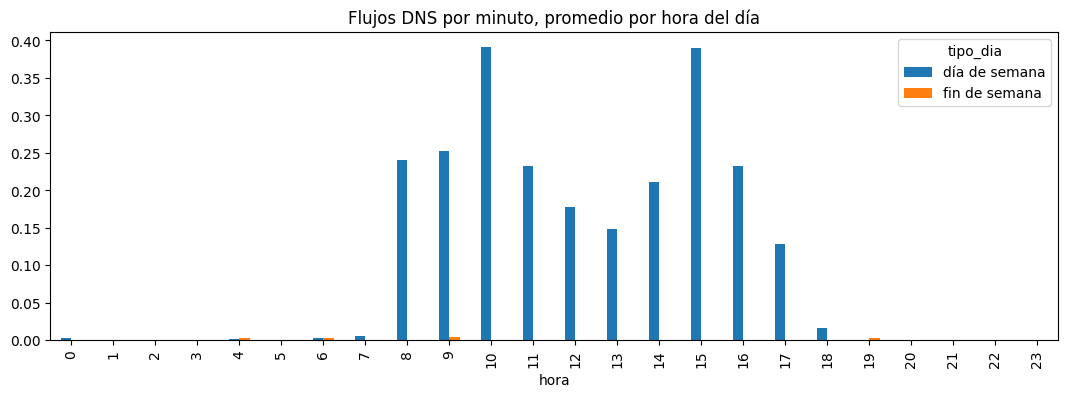

In [2]:
print(resumen(gold, IND).to_string())
perfil_horario(gold, IND).plot(kind="bar", figsize=(13, 4), title="Flujos DNS por minuto, promedio por hora del día")
plt.show()

## 2. Diagnóstico: ¿quién consulta y cuánto pesa el DNS?

In [3]:
dns = silver.where((F.col("dport") == 53) | (F.col("sport") == 53))
total, n_dns = silver.count(), dns.count()
print(f"Flujos DNS: {n_dns:,} de {total:,} ({100 * n_dns / total:.1f} % de todas las conexiones)")

por_host = (dns.groupBy("src").agg(F.count("*").alias("consultas"),
                                   F.avg(F.col("bytes_fwd")).alias("bytes_pregunta_prom"),
                                   F.avg(F.col("bytes_bwd")).alias("bytes_respuesta_prom"))
            .orderBy(F.desc("consultas")).limit(10).toPandas())
print("Hosts (seudonimizados) con más consultas DNS:")
print(por_host.round(1).to_string(index=False))

Flujos DNS: 2,842 de 397,354 (0.7 % de todas las conexiones)


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Hosts (seudonimizados) con más consultas DNS:
           src  consultas  bytes_pregunta_prom  bytes_respuesta_prom
h-4553a27eb3a6       1545                395.3                   0.0
h-589f657278d9        214                  0.0                 440.0
h-682bf17f533a        191                421.5                   0.0
h-e9ed28ba4f05        177                 51.4                 509.6
h-8cdf3c0103e0        146                  0.0                 426.0
h-709be3a16ae5         72                122.5                   0.0
h-00f9ee60e6c2         46                137.2                   0.0
h-9c3970337fb2         41                  0.0                  10.0
h-88560d7afaa0         38                  0.0                 410.3
h-eb4376aba41b         34                  0.0                 541.8


Un túnel DNS se reconoce porque las **preguntas** son anormalmente grandes
(los datos viajan escondidos en el nombre consultado). Distribución del tamaño
de las preguntas:

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


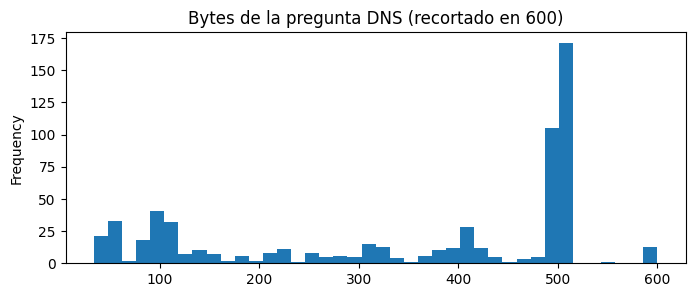

p99 del tamaño de pregunta: 936 bytes; preguntas por encima merecen revisión


In [4]:
tamanos = dns.select("bytes_fwd").where(F.col("bytes_fwd") > 0).sample(0.3, seed=42).toPandas()
tamanos["bytes_fwd"].clip(upper=600).plot(kind="hist", bins=40, figsize=(8, 3),
                                          title="Bytes de la pregunta DNS (recortado en 600)")
plt.show()
p99 = dns.select(F.expr("percentile_approx(bytes_fwd, 0.99)")).first()[0]
print(f"p99 del tamaño de pregunta: {p99} bytes; preguntas por encima merecen revisión")

In [5]:
print("Minutos con más DNS de lo normal para su hora:")
print(picos(gold, IND).to_string(index=False))

Minutos con más DNS de lo normal para su hora:


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


     ventana_inicio  dns  media_de_esa_hora    z
2026-08-08 19:44:00    1                0.0 36.6
2026-08-11 00:33:00    2                0.0 36.6
2026-08-10 06:04:00    2                0.0 32.8
2026-07-02 07:52:00    2                0.0 27.4
2026-08-15 04:56:00    1                0.0 25.9
2026-08-12 04:18:00    1                0.0 25.9
2026-07-02 09:17:00   21                0.2 22.6
2026-08-10 18:09:00    2                0.0 16.9
2026-07-01 18:58:00    2                0.0 16.9
2026-08-08 06:34:00    1                0.0 16.4


## 3. Predictivo U1: flujos DNS de la próxima hora (batch)

In [6]:
tabla, horas = modelo_horario(gold, IND)
print(f"{horas} horas consecutivas, división cronológica 80/20")
print(tabla.to_string())

26/10/30 00:52:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:52:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:52:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:52:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

26/10/30 00:52:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


...

26/10/30 00:53:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


740 horas consecutivas, división cronológica 80/20
                     rmse    mae     r2  mejora_vs_persistencia_%
persistencia       10.148  4.149  0.131                     0.000
linear_regression   8.939  4.274  0.326                    11.918
random_forest       8.674  3.985  0.365                    14.530


26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:53:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

## 4. U2: el modelo que corre en vivo (por minuto)

In [7]:
m, test, cv = metricas_streaming(IND)
print(f"Ganador: {m['ganador']} (escala {m['escala']}) | filas: {m['filas_total']:,}")
print(test.to_string())
print("\nBúsqueda de hiperparámetros (RMSE promedio de validación):")
print(cv.head(8).to_string(index=False))
print("\nVariables más importantes:", m["importancia_variables"])

Ganador: random_forest (escala log) | filas: 26,316
                    rmse    mae     r2  mejora_vs_persistencia_%
persistencia       0.733  0.170 -0.228                      0.00
linear_regression  0.595  0.148  0.191                     18.83
random_forest      0.604  0.144  0.167                     17.60
gbt                0.593  0.143  0.196                     19.10

Búsqueda de hiperparámetros (RMSE promedio de validación):
           modelo   escala  regParam  rmse_cv  numTrees  maxDepth  maxIter
linear_regression      log       0.1    0.336       NaN       NaN      NaN
    random_forest      log       NaN    0.336      40.0       6.0      NaN
    random_forest      log       NaN    0.337      40.0      10.0      NaN
linear_regression      log       0.0    0.338       NaN       NaN      NaN
              gbt      log       NaN    0.350       NaN       3.0     50.0
    random_forest original       NaN    0.360      40.0       6.0      NaN
linear_regression original       0.1  

## 5. Conclusiones
- **El DNS es poco frecuente en esta captura:** 2842 flujos (0,7 % de las
  conexiones), 0,08 por minuto en promedio, máximo 24 en un minuto.
- **Hallazgo a revisar:** un solo host (el primero de la tabla) concentra 1545 de
  las 2842 consultas, con preguntas de ~395 bytes en promedio y **sin
  respuesta registrada**. Preguntas así de grandes y repetidas son el patrón
  que se vigila en túneles DNS; no prueba un ataque, pero es exactamente lo
  que la mesa de TI debería revisar.
- **p99 del tamaño de pregunta: 936 bytes**; por encima, revisar.
- **U1 (por hora):** el Random Forest mejora 14,5 % frente a la persistencia.
- **U2 (por minuto):** RF en escala log, +17,6 %. En Grafana (fila
  "Dimensión 4") se ve el DNS real, su predicción, la persistencia y el umbral.